# Integritate si profilarea cohortului

**Scop:** verificarea calitatii datelor, distributia claselor pe subiecti si sesiuni, statistici separate pentru canalele EEG vs auxiliare (`ECG`, `EOG`) si explorarea grafica a semnalelor.

**Input-uri:** `data/manifest.parquet`, `data/data_sub_*.parquet`, `data/data_sub_*.npz`, `config.py`.

**Output-uri:** tabele CSV si raport Markdown in `reports/metrics/`, plus grafice in `reports/figures/eda/`.

**Regula de memorie:** incarcam **un singur subiect pe rand** si eliberam memoria (`del`, `gc.collect()`) dupa fiecare pas.

# 2.1 Pregatirea mediului

Importam librariile necesare, incarcam `config.py` si setam pragurile simple de verificare.

In [ ]:
%pip install -r ../requirements.txt

In [64]:
# Import necessary libraries

import gc
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import warnings as wn
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
from pathlib import Path

In [65]:
# Ignore all warnings

wn.filterwarnings("ignore")

In [66]:
# Import configuration module

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

import config as cfg
cfg.ensure_directories()

In [67]:
# Create simple settings and folders

FLATLINE_THRESHOLD = 1e-8
EXTREME_VAR_MULTIPLIER = 5.0
LOW_VAR_MULTIPLIER = 0.1
SEED = cfg.RANDOM_SEED

rng = np.random.default_rng(SEED)
FIG_DIR = cfg.FIGURES_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

print("Folder grafice:", cfg.to_relative_path(FIG_DIR))

Folder grafice: reports/figures/eda


# 2.2 Incarcarea manifestului si lista de subiecti

Citim `data/manifest.parquet` generat in notebook-ul 00 si pastram doar subiectii utilizabili (`usable == True`).

In [68]:
# Load manifest and get usable subject IDs

manifest = pd.read_parquet(cfg.MANIFEST_PATH)
subjects = sorted(manifest[manifest["usable"]]["subject_id"].unique().tolist())

print("Subiecti utilizabili:", subjects)
manifest[["subject_id", "format", "n_trials", "n_channels", "n_samples", "sfreq", "sessions", "usable"]]

Subiecti utilizabili: [1, 2, 3]


,subject_id,format,n_trials,n_channels,n_samples,sfreq,sessions,usable
0,1,npz,600,64,4001,1000.0,"0,1,2",True
1,1,parquet,600,64,4001,1000.0,"0,1,2",True
2,2,npz,600,64,4001,1000.0,"0,1,2",True
3,2,parquet,600,64,4001,1000.0,"0,1,2",True
4,3,npz,600,64,4001,1000.0,"0,1,2",True
5,3,parquet,600,64,4001,1000.0,"0,1,2",True


# 2.3 Audit simplu pe Parquet cu Dask (null, randuri, intervale)

Citim pe rand fiecare fisier Parquet cu Dask, redenumim coloanele `ch_*` cu `cfg.CHANNEL_MAP` si verificam valorile lipsa si limitele semnalului.

In [69]:
# Simple function to check one Parquet file with Dask

def check_parquet(sub_id):
    pq_path = cfg.get_subject_parquet_path(sub_id)
    ddf = dd.read_parquet(pq_path, engine=cfg.PARQUET_ENGINE)
    ddf = ddf.rename(columns=cfg.CHANNEL_MAP)
    aux_cols = cfg.ECG_CHANNELS + cfg.EOG_CHANNELS

    n_rows, nulls, n_trials, ts_min, ts_max, eeg_min, eeg_max, aux_min, aux_max = dask.compute(
        ddf.shape[0],
        ddf.isnull().sum().sum(),
        ddf["trial"].nunique(),
        ddf["timestamp"].min(),
        ddf["timestamp"].max(),
        ddf[cfg.EEG_CHANNELS].min().min(),
        ddf[cfg.EEG_CHANNELS].max().max(),
        ddf[aux_cols].min().min(),
        ddf[aux_cols].max().max(),
    )

    n_samples = int(ts_max) - int(ts_min) + 1
    return {
        "subject_id": int(sub_id),
        "pq_rows": int(n_rows),
        "pq_trials": int(n_trials),
        "pq_samples": n_samples,
        "rows_ok": int(n_rows) == int(n_trials) * n_samples,
        "nulls": int(nulls),
        "eeg_min": float(eeg_min),
        "eeg_max": float(eeg_max),
        "aux_min": float(aux_min),
        "aux_max": float(aux_max),
    }

In [70]:
# Run Parquet checks for each subject

pq_rows = []
for sub_id in subjects:
    info = check_parquet(sub_id)
    pq_rows.append(info)
    print(f"Subiect {sub_id:02d}: randuri={info['pq_rows']}, nulls={info['nulls']}, EEG=[{info['eeg_min']:.4f}, {info['eeg_max']:.4f}], AUX=[{info['aux_min']:.1f}, {info['aux_max']:.1f}]")

pq_df = pd.DataFrame(pq_rows)

Subiect 01: randuri=2400600, nulls=0, EEG=[-0.1649, 0.1869], AUX=[-375.0, 185.3]
Subiect 02: randuri=2400600, nulls=0, EEG=[-0.1991, 0.1927], AUX=[-375.0, 226.5]
Subiect 03: randuri=2400600, nulls=0, EEG=[-0.2002, 0.1489], AUX=[-375.0, 262.5]


In [71]:
# Show the parquet dataframe
pq_df

,subject_id,pq_rows,pq_trials,pq_samples,rows_ok,nulls,eeg_min,eeg_max,aux_min,aux_max
0,1,2400600,600,4001,True,0,-0.164860,0.186856,-375.0,185.344437
1,2,2400600,600,4001,True,0,-0.199141,0.192733,-375.0,226.498108
2,3,2400600,600,4001,True,0,-0.200235,0.148855,-375.0,262.516296


# 2.4 Distributia claselor si sesiunilor (NPZ)

Citim doar etichetele `y` si `metadata` (`subject`, `session`, `run`) din fisierele NPZ pentru a numara trialurile reale pe fiecare sesiune si clasa.

In [72]:
# Count observed trials per subject, session, and class

class_rows = []
trial_rows = []

for sub_id in subjects:
    data = np.load(cfg.get_subject_npz_path(sub_id), allow_pickle=True)
    y = data["y"].astype(str)
    meta = data["metadata"]
    sessions = [str(row[1]) for row in meta]

    df_sub = pd.DataFrame({"subject_id": sub_id, "session": sessions, "label": y})
    counts = df_sub.groupby(["subject_id", "session", "label"]).size().reset_index(name="n_trials")
    class_rows.append(counts)

    pq_trials = int(pq_df.loc[pq_df["subject_id"] == sub_id, "pq_trials"].iloc[0])
    trial_rows.append({
        "subject_id": sub_id,
        "npz_trials": len(y),
        "n_sessions": len(set(sessions)),
        "sessions": ",".join(sorted(set(sessions))),
        "match_parquet": len(y) == pq_trials,
    })
    print(f"Subiect {sub_id:02d}: {len(y)} trialuri, sesiuni={sorted(set(sessions))}, coincide_parquet={len(y) == pq_trials}")

    del data, y, meta, df_sub
    gc.collect()

class_df = pd.concat(class_rows, ignore_index=True)
trial_df = pd.DataFrame(trial_rows)

Subiect 01: 600 trialuri, sesiuni=['0', '1', '2'], coincide_parquet=True
Subiect 02: 600 trialuri, sesiuni=['0', '1', '2'], coincide_parquet=True
Subiect 03: 600 trialuri, sesiuni=['0', '1', '2'], coincide_parquet=True


In [73]:
# Show class counts table per subject and session

class_df.pivot_table(index=["subject_id", "session"], columns="label", values="n_trials", fill_value=0)

label               left_hand  right_hand
subject_id session                       
1          0            100.0       100.0
           1            100.0       100.0
           2            100.0       100.0
2          0            100.0       100.0
           1            100.0       100.0
           2            100.0       100.0
3          0            100.0       100.0
           1            100.0       100.0
           2            100.0       100.0

# 2.5 Statistici per canal (EEG vs Auxiliare) si anomalii

Calculam statisticile pe fiecare canal (`mean`, `std`, `var`, `min`, `p05`, `p50`, `p95`, `max`, `range`) si verificam valorile `NaN`/`Inf`, canalele `flatline` si canalele EEG cu varianta extrema.

In [74]:
# Simple helper to assign a scalp region to each channel

def get_region(ch_name):
    if ch_name in cfg.ECG_CHANNELS or ch_name in cfg.EOG_CHANNELS:
        return "Aux"
    if ch_name.startswith(("Fp", "AF", "F")) and not ch_name.startswith(("FC", "FT")):
        return "Frontal"
    if ch_name.startswith(("FC", "FT", "C", "T")) and not ch_name.startswith(("CP", "TP")):
        return "Central/Motor"
    if ch_name.startswith(("CP", "TP", "P")):
        return "Parietal"
    return "Occipital"

In [75]:
# Simple function to compute channel stats for one subject

def get_channel_stats(sub_id):
    data = np.load(cfg.get_subject_npz_path(sub_id), allow_pickle=True)
    X = data["X"]

    n_nan = int(np.isnan(X).sum())
    n_inf = int(np.isinf(X).sum())
    rows = []

    for i, ch_name in enumerate(cfg.MED_COLUMNS):
        vals = X[:, i, :]
        p05, p50, p95 = np.percentile(vals, [5, 50, 95])
        ch_std = float(np.std(vals))
        ch_min = float(np.min(vals))
        ch_max = float(np.max(vals))
        flat_trials = int((vals.std(axis=1) <= FLATLINE_THRESHOLD).sum())

        rows.append({
            "subject_id": sub_id,
            "channel": ch_name,
            "type": cfg.CHANNEL_TYPES[ch_name],
            "region": get_region(ch_name),
            "mean": float(np.mean(vals)),
            "std": ch_std,
            "var": float(np.var(vals)),
            "min": ch_min,
            "p05": float(p05),
            "p50": float(p50),
            "p95": float(p95),
            "max": ch_max,
            "range": ch_max - ch_min,
            "flatline_trials": flat_trials,
            "is_flatline": ch_std <= FLATLINE_THRESHOLD,
        })

    del data, X
    gc.collect()

    df_ch = pd.DataFrame(rows)
    eeg_median_std = df_ch[df_ch["type"] == "eeg"]["std"].median()
    df_ch["is_extreme_var"] = (
        (df_ch["type"] == "eeg")
        & ((df_ch["std"] > EXTREME_VAR_MULTIPLIER * eeg_median_std) | (df_ch["std"] < LOW_VAR_MULTIPLIER * eeg_median_std))
    )
    return df_ch, n_nan, n_inf

In [76]:
# Run channel stats loop across all usable subjects

all_ch_dfs = []
quality_rows = []

for sub_id in subjects:
    df_ch, n_nan, n_inf = get_channel_stats(sub_id)
    all_ch_dfs.append(df_ch)
    quality_rows.append({
        "subject_id": sub_id,
        "n_nan": n_nan,
        "n_inf": n_inf,
        "flatline_channels": int(df_ch["is_flatline"].sum()),
        "partial_flatline_channels": int((df_ch["flatline_trials"] > 0).sum()),
        "extreme_var_eeg": int(df_ch["is_extreme_var"].sum()),
    })
    print(f"Subiect {sub_id:02d}: NaN={n_nan}, Inf={n_inf}, flatline={df_ch['is_flatline'].sum()}, partial_flat={int((df_ch['flatline_trials'] > 0).sum())}, extreme_eeg={df_ch['is_extreme_var'].sum()}")

channel_df = pd.concat(all_ch_dfs, ignore_index=True)
quality_df = pd.DataFrame(quality_rows)

Subiect 01: NaN=0, Inf=0, flatline=0, partial_flat=2, extreme_eeg=0
Subiect 02: NaN=0, Inf=0, flatline=0, partial_flat=2, extreme_eeg=0
Subiect 03: NaN=0, Inf=0, flatline=0, partial_flat=4, extreme_eeg=0


In [77]:
# Compare EEG channels vs Auxiliary channels separately
print("=== Sumar EEG (59 canale) ===")
display(channel_df[channel_df["type"] == "eeg"].groupby("subject_id")[["mean", "std", "var", "p05", "p50", "p95", "range"]].mean())

=== Sumar EEG (59 canale) ===


,mean,std,var,p05,p50,p95,range
subject_id,,,,,,,
1,1.561390e-07,0.002456,0.000006,-0.003878,0.000003,0.003870,0.104454
2,-2.625829e-07,0.005768,0.000036,-0.008472,0.000010,0.008471,0.170265
3,-6.971834e-07,0.003944,0.000017,-0.006316,-0.000004,0.006321,0.117641


In [78]:
# Auxilliary ECG / EOG
print("=== Sumar Auxiliare (ECG / EOG) ===")
display(channel_df[channel_df["type"] != "eeg"][["subject_id", "channel", "type", "mean", "std", "min", "max", "flatline_trials"]])

=== Sumar Auxiliare (ECG / EOG) ===


,subject_id,channel,type,mean,std,min,max,flatline_trials
59,1,ECG,ecg,-326.187632,79.029837,-375.000000,-58.441158,400
60,1,EOG1,eog,-182.616658,109.095732,-269.303703,-21.057331,0
61,1,EOG2,eog,-77.972233,58.472500,-138.973595,31.730155,0
62,1,EOG3,eog,41.753678,96.094302,-93.305049,185.344431,0
63,1,EOG4,eog,-201.121464,126.422740,-375.000000,-71.495068,200
123,2,ECG,ecg,-273.927892,146.266708,-375.000000,-37.002663,401
124,2,EOG1,eog,-284.320936,128.621512,-375.000000,-73.546868,400
125,2,EOG2,eog,-84.386909,131.313682,-313.411471,48.629324,0
126,2,EOG3,eog,140.611060,62.297670,46.017478,226.498103,0
127,2,EOG4,eog,68.179260,93.213729,-100.193633,208.005299,0


In [79]:
# Show any flagged channels (flatline, partial flatline, or extreme variance)

flagged_df = channel_df[
    channel_df["is_flatline"] | (channel_df["flatline_trials"] > 0) | channel_df["is_extreme_var"]
][["subject_id", "channel", "type", "std", "flatline_trials", "is_flatline", "is_extreme_var"]]

print(f"Canale semnalate: {len(flagged_df)}")
flagged_df

Canale semnalate: 8


,subject_id,channel,type,std,flatline_trials,is_flatline,is_extreme_var
59,1,ECG,ecg,79.029837,400,False,False
63,1,EOG4,eog,126.422740,200,False,False
123,2,ECG,ecg,146.266708,401,False,False
124,2,EOG1,eog,128.621512,400,False,False
156,3,C3,eeg,0.003397,36,False,False
187,3,ECG,ecg,146.469827,294,False,False
188,3,EOG1,eog,61.412625,400,False,False
191,3,EOG4,eog,92.288146,200,False,False


# 2.6 Vizualizari exploratorii

Generam o serie variata de grafice (pie/donut, bar, stacked bar, histograma+KDE, boxplot, violin, scatter, horizontal bar, linii cu interval std, heatmap, pairplot, topomap scalp, PSD Welch, jointplot, timeline per trial, carpet plot si ECDF) si le salvam in `reports/figures/eda/`.

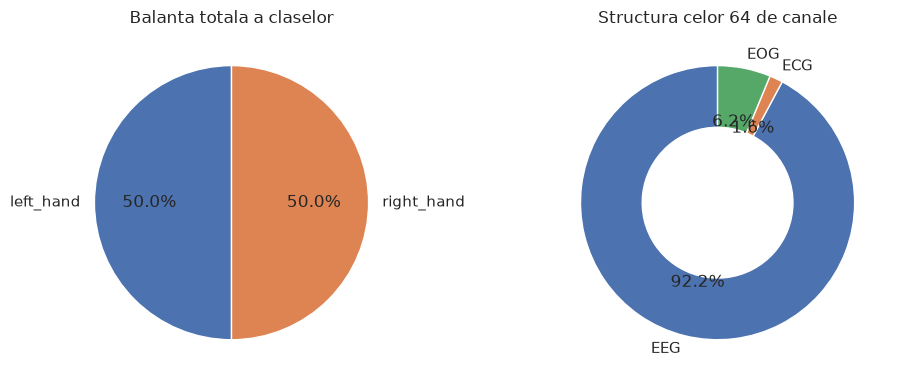

In [80]:
# Plot 1: Pie & Donut charts for overall class balance and channel types

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

label_totals = class_df.groupby("label")["n_trials"].sum()
axes[0].pie(label_totals.values, labels=label_totals.index, autopct="%1.1f%%", startangle=90, colors=["#4C72B0", "#DD8452"])
axes[0].set_title("Balanta totala a claselor")

ch_counts = cfg.get_channel_type_counts()
mod_names = ["EEG", "ECG", "EOG"]
mod_vals = [ch_counts["eeg"], ch_counts["ecg"], ch_counts["eog"]]
axes[1].pie(mod_vals, labels=mod_names, autopct="%1.1f%%", startangle=90, wedgeprops={"width": 0.45})
axes[1].set_title("Structura celor 64 de canale")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_overview_pies.png", dpi=150)
plt.show()
plt.close()

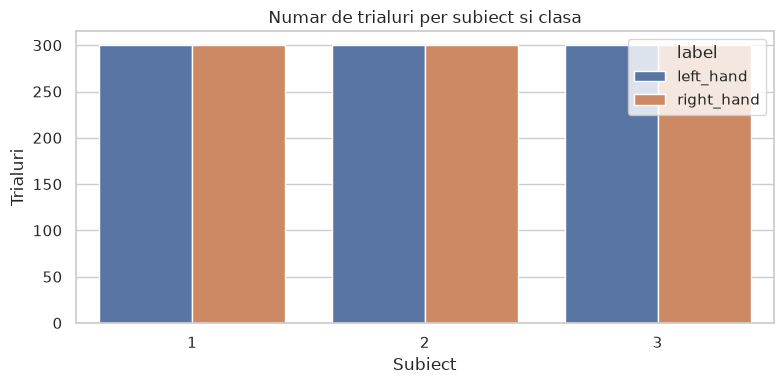

In [81]:
# Plot 2: Grouped bar chart of trial counts per subject and class

sub_cls = class_df.groupby(["subject_id", "label"])["n_trials"].sum().reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=sub_cls, x="subject_id", y="n_trials", hue="label")
plt.title("Numar de trialuri per subiect si clasa")
plt.xlabel("Subiect")
plt.ylabel("Trialuri")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_class_counts_per_subject.png", dpi=150)
plt.show()
plt.close()

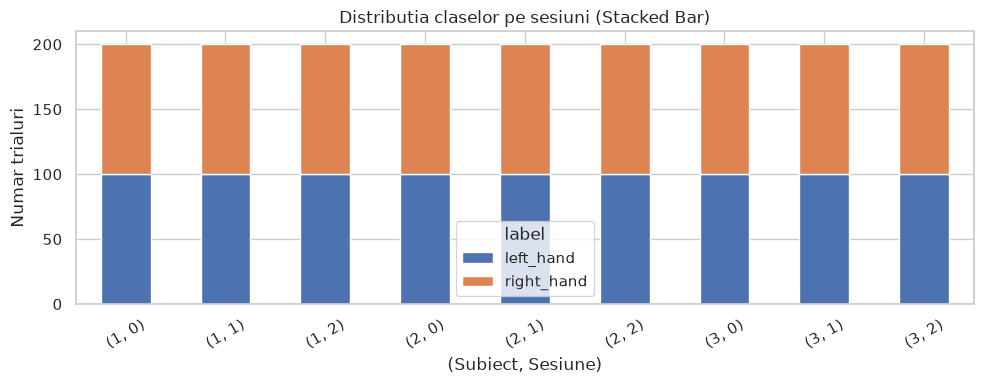

In [82]:
# Plot 3: Stacked bar chart of classes across subjects and sessions

piv = class_df.pivot_table(index=["subject_id", "session"], columns="label", values="n_trials", fill_value=0)
ax = piv.plot(kind="bar", stacked=True, figsize=(10, 4), color=["#4C72B0", "#DD8452"])
ax.set_title("Distributia claselor pe sesiuni (Stacked Bar)")
ax.set_xlabel("(Subiect, Sesiune)")
ax.set_ylabel("Numar trialuri")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_sessions_stacked_bar.png", dpi=150)
plt.show()
plt.close()

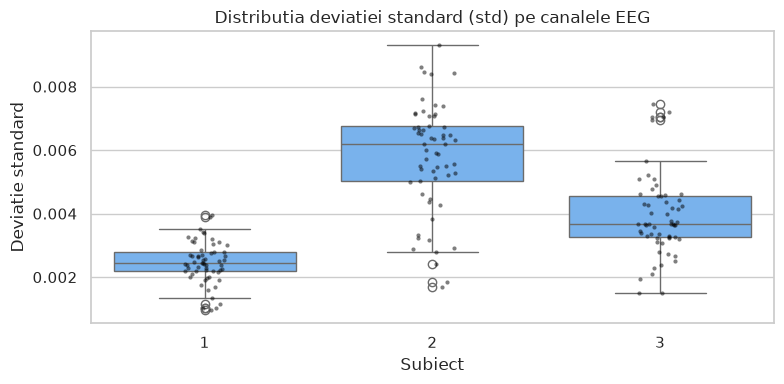

In [83]:
# Plot 5: Box plot of EEG channel standard deviation per subject

eeg_only = channel_df[channel_df["type"] == "eeg"]

plt.figure(figsize=(8, 4))
sns.boxplot(data=eeg_only, x="subject_id", y="std", color="#66B2FF")
sns.stripplot(data=eeg_only, x="subject_id", y="std", color="black", size=3, alpha=0.5)
plt.title("Distributia deviatiei standard (std) pe canalele EEG")
plt.xlabel("Subiect")
plt.ylabel("Deviatie standard")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_eeg_std_boxplot.png", dpi=150)
plt.show()
plt.close()

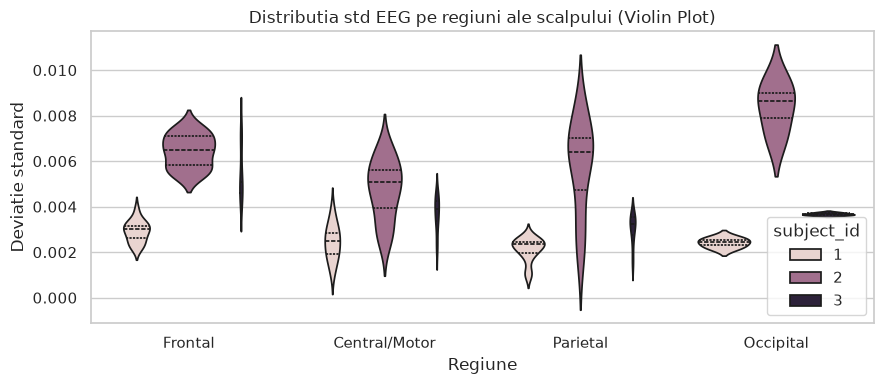

In [84]:
# Plot 6: Violin plot of EEG std across scalp regions

plt.figure(figsize=(9, 4))
sns.violinplot(data=eeg_only, x="region", y="std", hue="subject_id", inner="quartile")
plt.title("Distributia std EEG pe regiuni ale scalpului (Violin Plot)")
plt.xlabel("Regiune")
plt.ylabel("Deviatie standard")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_region_std_violin.png", dpi=150)
plt.show()
plt.close()

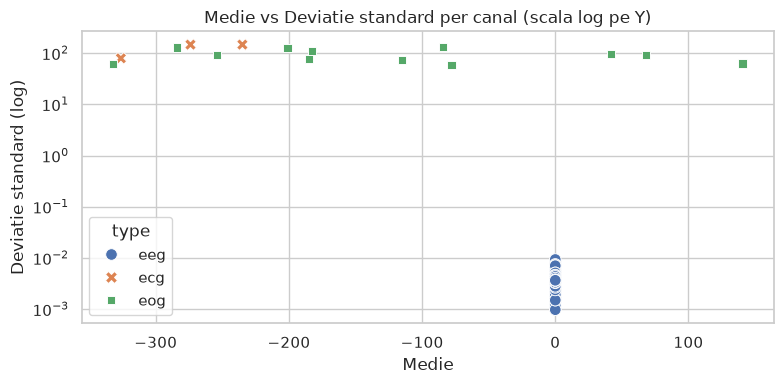

In [85]:
# Plot 7: Scatter plot of channel mean vs std (EEG vs ECG/EOG)

plt.figure(figsize=(8, 4))
sns.scatterplot(data=channel_df, x="mean", y="std", hue="type", style="type", s=70)
plt.yscale("log")
plt.title("Medie vs Deviatie standard per canal (scala log pe Y)")
plt.xlabel("Medie")
plt.ylabel("Deviatie standard (log)")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_mean_vs_std_scatter.png", dpi=150)
plt.show()
plt.close()

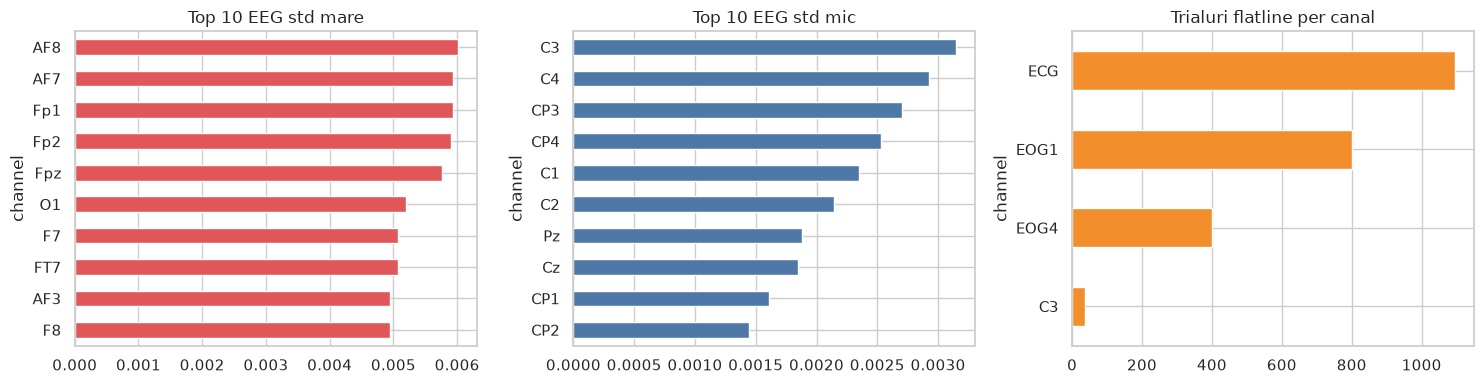

In [86]:
# Plot 8: Horizontal bar charts of Top 10 highest/lowest EEG std and partial flatlines

eeg_avg = eeg_only.groupby("channel")["std"].mean().sort_values()
top10 = eeg_avg.tail(10)
bot10 = eeg_avg.head(10)
flat_aux = channel_df.groupby("channel")["flatline_trials"].sum()
flat_aux = flat_aux[flat_aux > 0].sort_values()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
top10.plot(kind="barh", ax=axes[0], color="#E15759", title="Top 10 EEG std mare")
bot10.plot(kind="barh", ax=axes[1], color="#4E79A7", title="Top 10 EEG std mic")
if len(flat_aux) > 0:
    flat_aux.plot(kind="barh", ax=axes[2], color="#F28E2B", title="Trialuri flatline per canal")
else:
    axes[2].text(0.5, 0.5, "Niciun trial flatline", ha="center", va="center")
    axes[2].set_title("Trialuri flatline per canal")

plt.tight_layout()
plt.savefig(FIG_DIR / "08_top_bottom_var_channels.png", dpi=150)
plt.show()
plt.close()

In [87]:
# Load one representative subject temporarily for signal plots (4, 9, 10, 11, 12)

rep_sub = subjects[0]
rep_data = np.load(cfg.get_subject_npz_path(rep_sub), allow_pickle=True)
X_rep = rep_data["X"]
y_rep = rep_data["y"].astype(str)
print(f"Incarcat temporar subiect {rep_sub:02d} pentru grafice: shape={X_rep.shape}")

Incarcat temporar subiect 01 pentru grafice: shape=(600, 64, 4001)


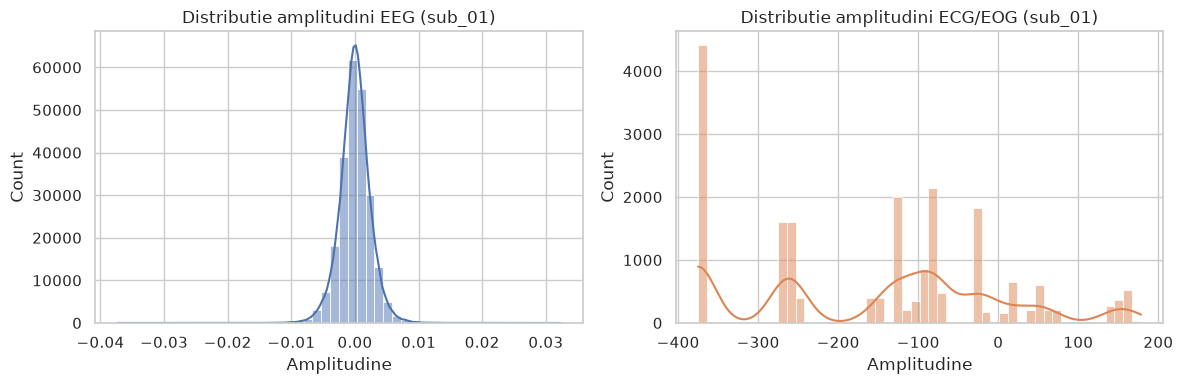

In [88]:
# Plot 4: Histogram + KDE of EEG vs Auxiliary amplitudes (sample trials)

sample_idx = rng.choice(X_rep.shape[0], size=10, replace=False)
eeg_sample_vals = X_rep[sample_idx, :59, ::10].ravel()
aux_sample_vals = X_rep[sample_idx, 59:, ::10].ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(eeg_sample_vals, bins=50, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Distributie amplitudini EEG (sub_{rep_sub:02d})")
axes[0].set_xlabel("Amplitudine")

sns.histplot(aux_sample_vals, bins=50, kde=True, ax=axes[1], color="#DD8452")
axes[1].set_title(f"Distributie amplitudini ECG/EOG (sub_{rep_sub:02d})")
axes[1].set_xlabel("Amplitudine")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_amplitude_hist_kde.png", dpi=150)
plt.show()
plt.close()

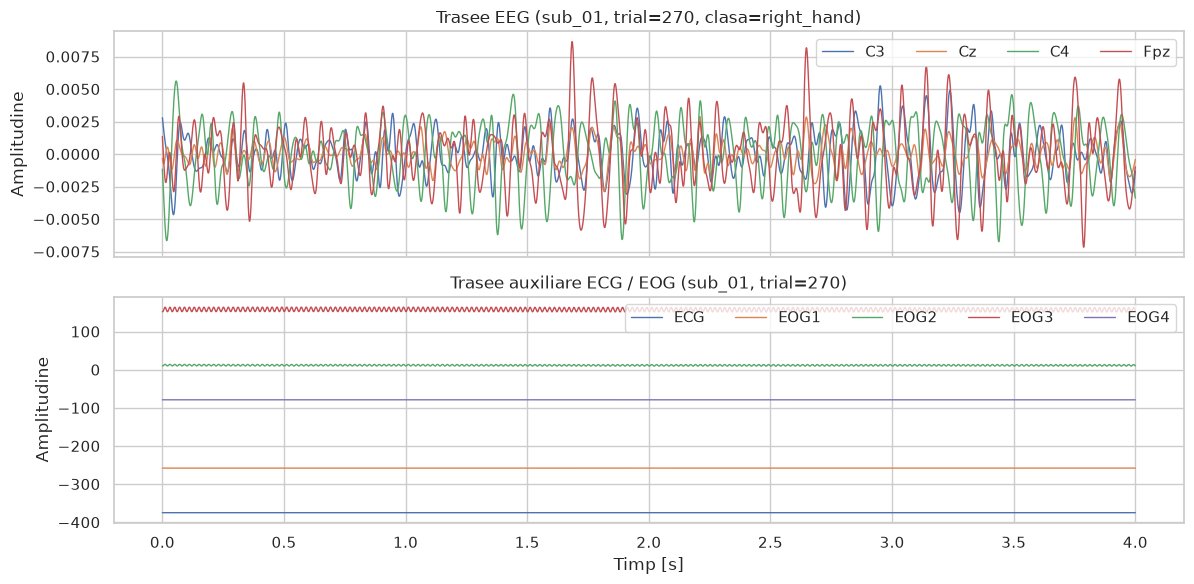

In [89]:
# Plot 9: Line plots of EEG and Aux waveforms for one sample trial

t_idx = int(rng.integers(0, X_rep.shape[0]))
time_sec = np.arange(X_rep.shape[2]) / cfg.EXPECTED_SFREQ_HZ

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ch in ["C3", "Cz", "C4", "Fpz"]:
    axes[0].plot(time_sec, X_rep[t_idx, cfg.MED_COLUMNS.index(ch), :], label=ch, linewidth=1.0)
axes[0].set_title(f"Trasee EEG (sub_{rep_sub:02d}, trial={t_idx}, clasa={y_rep[t_idx]})")
axes[0].set_ylabel("Amplitudine")
axes[0].legend(loc="upper right", ncol=4)

for ch in ["ECG", "EOG1", "EOG2", "EOG3", "EOG4"]:
    axes[1].plot(time_sec, X_rep[t_idx, cfg.MED_COLUMNS.index(ch), :], label=ch, linewidth=1.0)
axes[1].set_title(f"Trasee auxiliare ECG / EOG (sub_{rep_sub:02d}, trial={t_idx})")
axes[1].set_xlabel("Timp [s]")
axes[1].set_ylabel("Amplitudine")
axes[1].legend(loc="upper right", ncol=5)

plt.tight_layout()
plt.savefig(FIG_DIR / "09_sample_eeg_and_aux_traces.png", dpi=150)
plt.show()
plt.close()

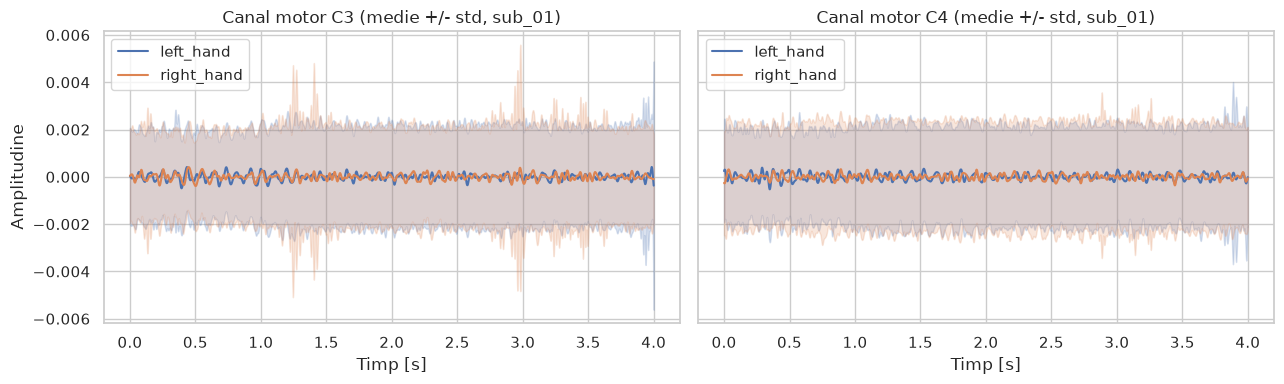

In [90]:
# Plot 10: Mean +/- std shaded line plots on motor channels C3 and C4

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, ch in zip(axes, ["C3", "C4"]):
    ch_i = cfg.MED_COLUMNS.index(ch)
    for lbl, col in [("left_hand", "#4C72B0"), ("right_hand", "#DD8452")]:
        sig = X_rep[y_rep == lbl, ch_i, :]
        m = sig.mean(axis=0)
        s = sig.std(axis=0)
        ax.plot(time_sec, m, label=lbl, color=col)
        ax.fill_between(time_sec, m - s, m + s, color=col, alpha=0.2)
    ax.set_title(f"Canal motor {ch} (medie +/- std, sub_{rep_sub:02d})")
    ax.set_xlabel("Timp [s]")
    ax.legend()
axes[0].set_ylabel("Amplitudine")

plt.tight_layout()
plt.savefig(FIG_DIR / "10_motor_c3_c4_mean_std.png", dpi=150)
plt.show()
plt.close()

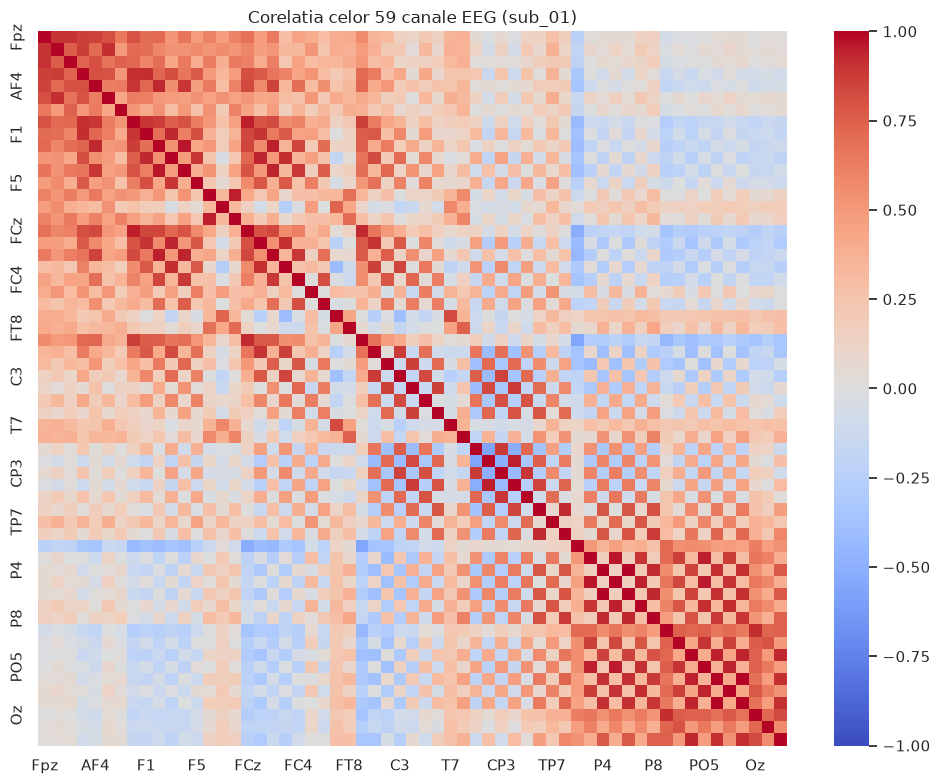

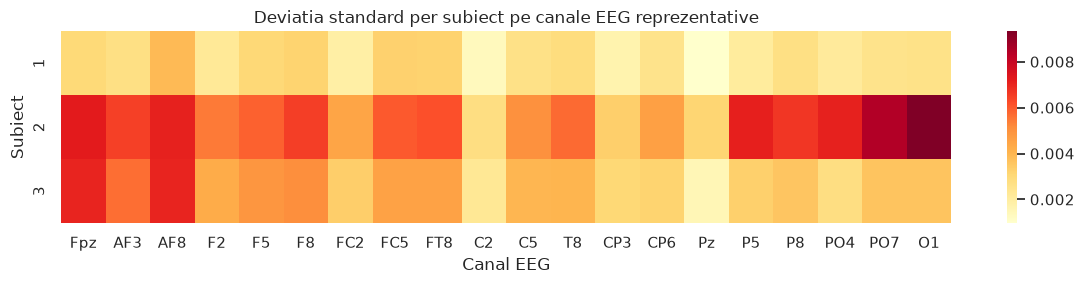

In [91]:
# Plot 11: Heatmaps (EEG channel correlation + std across subjects)

corr_idx = rng.choice(X_rep.shape[0], size=30, replace=False)
eeg_flat = X_rep[corr_idx, :59, :].transpose(1, 0, 2).reshape(59, -1)
corr_df = pd.DataFrame(np.corrcoef(eeg_flat), index=cfg.EEG_CHANNELS, columns=cfg.EEG_CHANNELS)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=4, yticklabels=4)
plt.title(f"Corelatia celor 59 canale EEG (sub_{rep_sub:02d})")
plt.tight_layout()
plt.savefig(FIG_DIR / "11a_eeg_correlation_heatmap.png", dpi=150)
plt.show()
plt.close()

std_matrix = eeg_only.pivot(index="subject_id", columns="channel", values="std")[cfg.EEG_CHANNELS[::3]]
plt.figure(figsize=(12, 3))
sns.heatmap(std_matrix, cmap="YlOrRd", annot=False)
plt.title("Deviatia standard per subiect pe canale EEG reprezentative")
plt.xlabel("Canal EEG")
plt.ylabel("Subiect")
plt.tight_layout()
plt.savefig(FIG_DIR / "11b_subject_channel_std_heatmap.png", dpi=150)
plt.show()
plt.close()

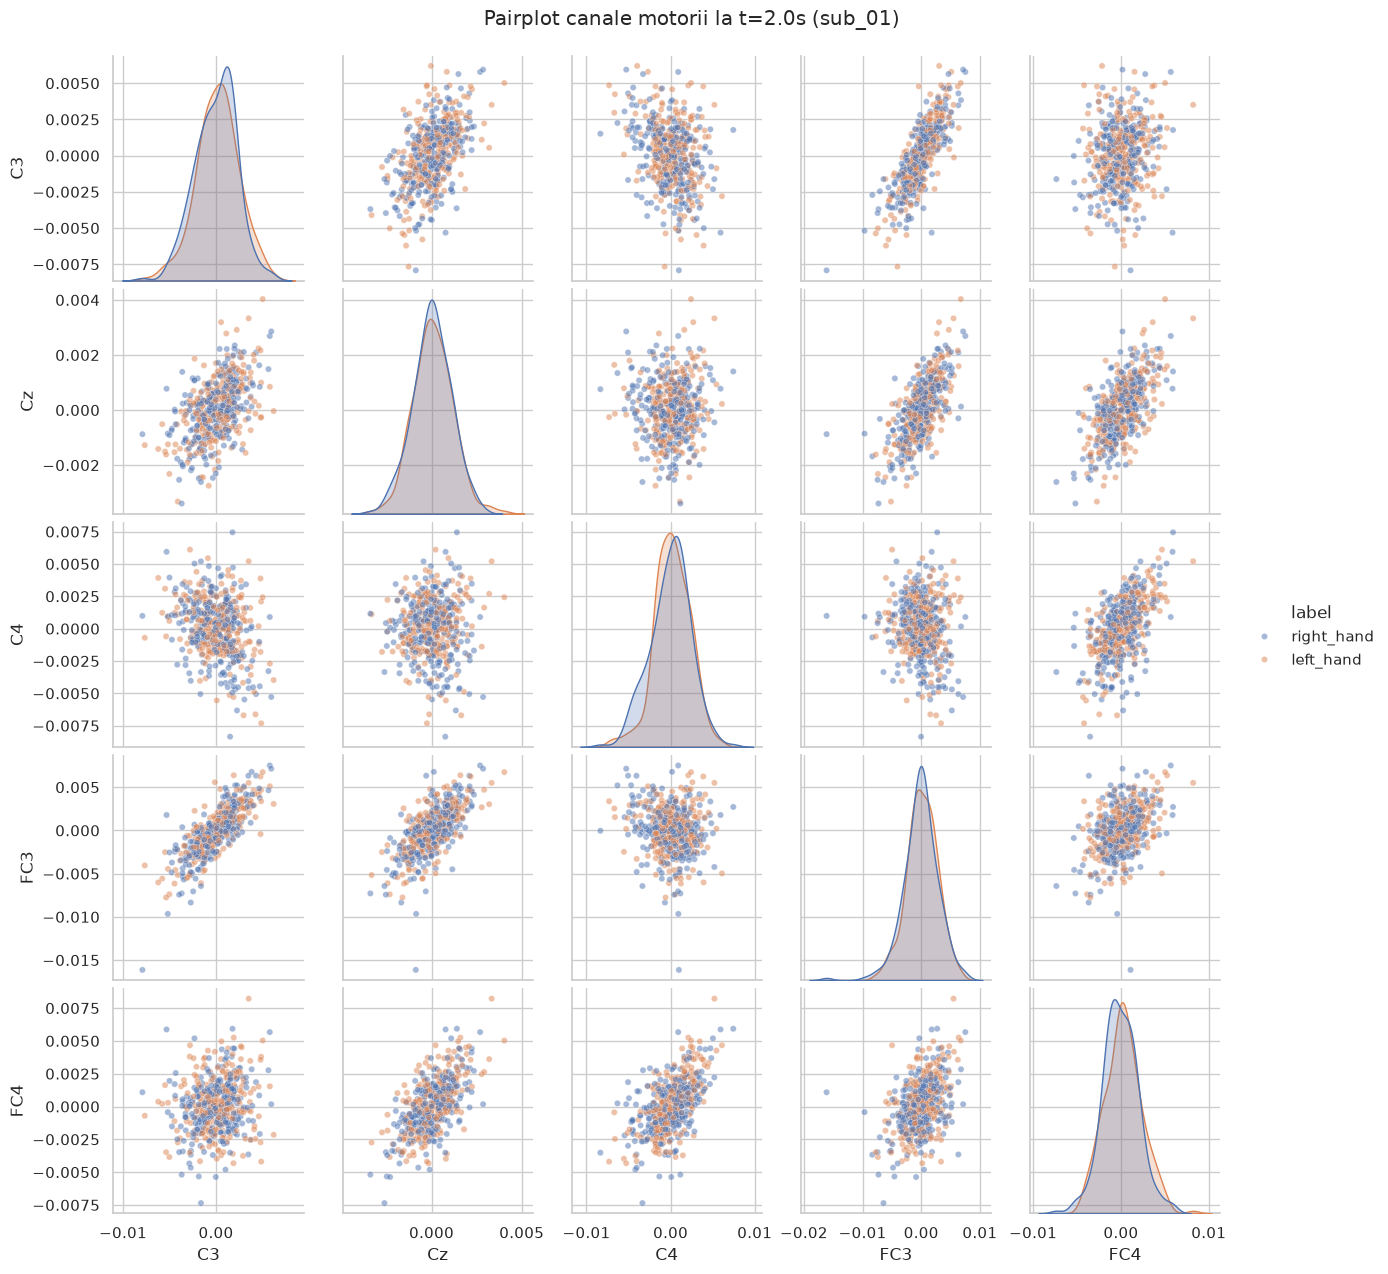

In [92]:
# Plot 12: Pairplot on key motor channels (reproducible 500-point sample)

motor_chs = ["C3", "Cz", "C4", "FC3", "FC4"]
motor_idx = [cfg.MED_COLUMNS.index(ch) for ch in motor_chs]
pair_trials = rng.choice(X_rep.shape[0], size=500, replace=False)
t_mid = X_rep.shape[2] // 2

pair_df = pd.DataFrame(X_rep[pair_trials][:, motor_idx, t_mid], columns=motor_chs)
pair_df["label"] = y_rep[pair_trials]

g = sns.pairplot(pair_df, hue="label", plot_kws={"alpha": 0.5, "s": 20})
g.figure.suptitle(f"Pairplot canale motorii la t=2.0s (sub_{rep_sub:02d})", y=1.02)
g.savefig(FIG_DIR / "12_motor_channels_pairplot.png", dpi=150)
plt.show()
plt.close()

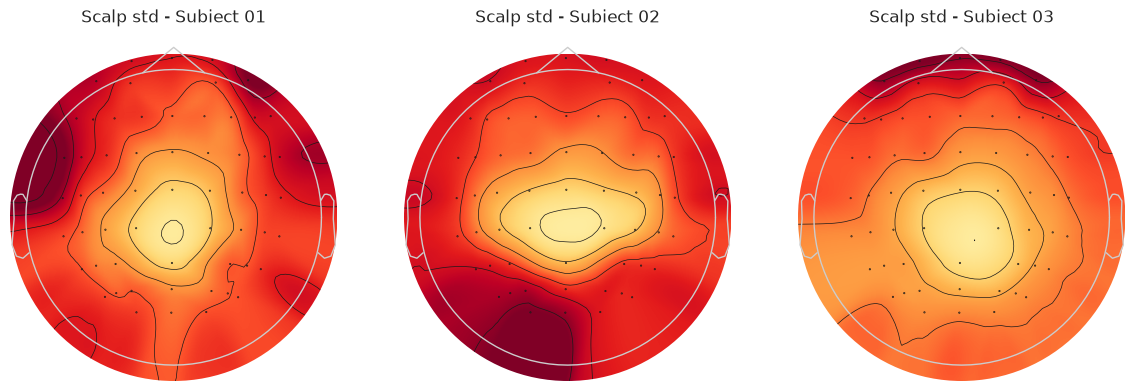

In [93]:
# Plot 13: 2D scalp topomap of EEG channel std across subjects

import mne

info = mne.create_info(cfg.EEG_CHANNELS, sfreq=cfg.EXPECTED_SFREQ_HZ, ch_types="eeg")
info.set_montage("standard_1005")

fig, axes = plt.subplots(1, len(subjects), figsize=(4 * len(subjects), 4))
if len(subjects) == 1:
    axes = [axes]

for ax, sub_id in zip(axes, subjects):
    sub_eeg = channel_df[(channel_df["subject_id"] == sub_id) & (channel_df["type"] == "eeg")]
    sub_stds = sub_eeg.set_index("channel").loc[cfg.EEG_CHANNELS, "std"].to_numpy()
    mne.viz.plot_topomap(sub_stds, info, axes=ax, show=False, cmap="YlOrRd")
    ax.set_title(f"Scalp std - Subiect {sub_id:02d}")

plt.tight_layout()
plt.savefig(FIG_DIR / "13_scalp_std_topomap.png", dpi=150)
plt.show()
plt.close()

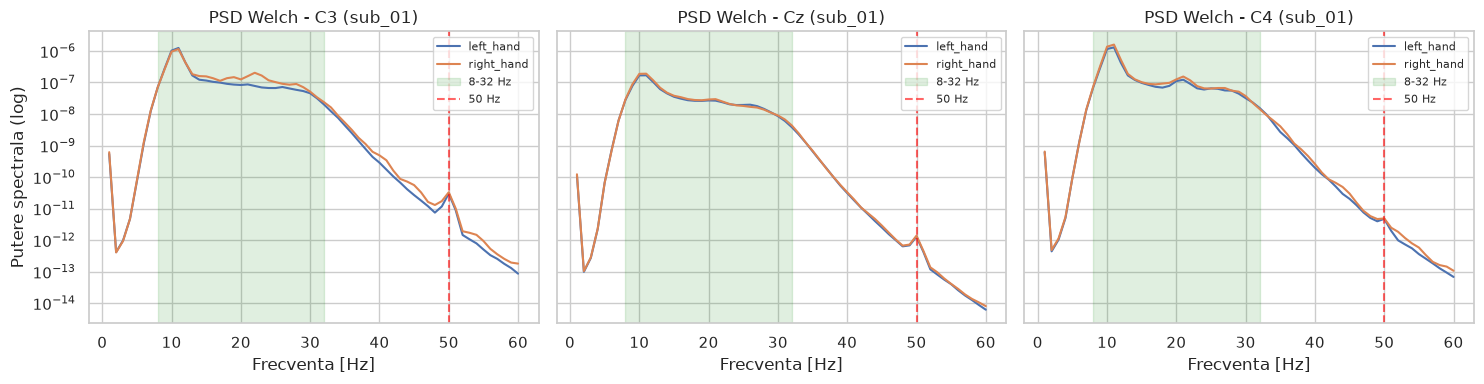

In [94]:
# Plot 14: Welch power spectrum (1-60 Hz) on C3, Cz, C4 to check 8-32 Hz band

from scipy.signal import welch

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, ch in zip(axes, ["C3", "Cz", "C4"]):
    ch_i = cfg.MED_COLUMNS.index(ch)
    for lbl, col in [("left_hand", "#4C72B0"), ("right_hand", "#DD8452")]:
        freqs, psd = welch(X_rep[y_rep == lbl, ch_i, :], fs=cfg.EXPECTED_SFREQ_HZ, nperseg=1000, axis=1)
        mean_psd = psd.mean(axis=0)
        mask = (freqs >= 1) & (freqs <= 60)
        ax.semilogy(freqs[mask], mean_psd[mask], label=lbl, color=col)
    ax.axvspan(cfg.FMIN, cfg.FMAX, color="green", alpha=0.12, label="8-32 Hz")
    ax.axvline(50, color="red", linestyle="--", alpha=0.6, label="50 Hz")
    ax.set_title(f"PSD Welch - {ch} (sub_{rep_sub:02d})")
    ax.set_xlabel("Frecventa [Hz]")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Putere spectrala (log)")

plt.tight_layout()
plt.savefig(FIG_DIR / "14_welch_psd_bandcheck.png", dpi=150)
plt.show()
plt.close()

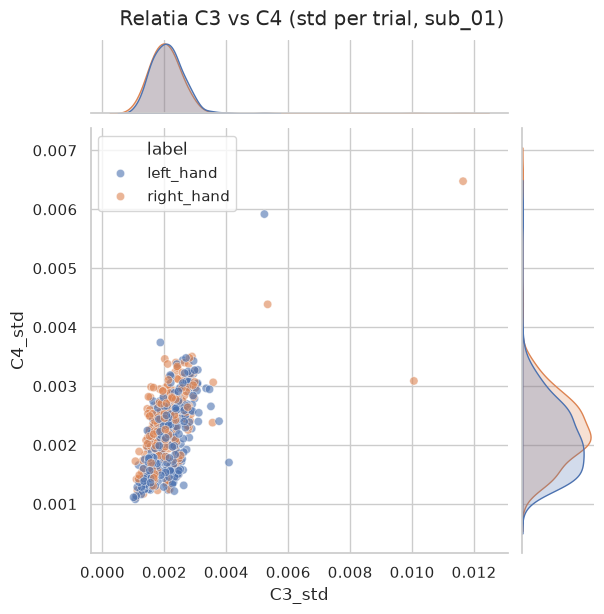

In [95]:
# Plot 15: Jointplot of C3 vs C4 trial-level std by class

c3_std = X_rep[:, cfg.MED_COLUMNS.index("C3"), :].std(axis=1)
c4_std = X_rep[:, cfg.MED_COLUMNS.index("C4"), :].std(axis=1)
joint_df = pd.DataFrame({"C3_std": c3_std, "C4_std": c4_std, "label": y_rep})

g = sns.jointplot(data=joint_df, x="C3_std", y="C4_std", hue="label", alpha=0.6, height=6)
g.figure.suptitle(f"Relatia C3 vs C4 (std per trial, sub_{rep_sub:02d})", y=1.02)
g.savefig(FIG_DIR / "15_c3_vs_c4_jointplot.png", dpi=150)
plt.show()
plt.close()

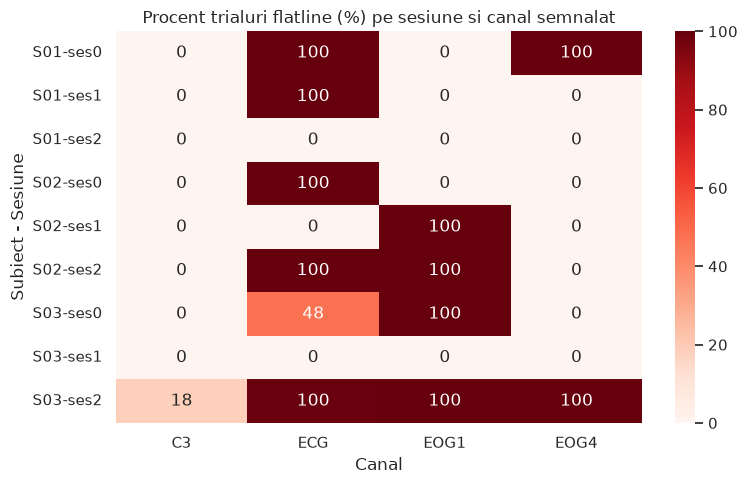

In [96]:
# Plot 16: Heatmap of flatline trial percentage per subject, session, and flagged channel

check_chs = sorted(flagged_df["channel"].unique().tolist())
if len(check_chs) > 0:
    heat_rows = []
    for sub_id in subjects:
        d = np.load(cfg.get_subject_npz_path(sub_id), allow_pickle=True)
        X_tmp = d["X"]
        sessions_tmp = np.array([str(r[1]) for r in d["metadata"]])
        for ses in sorted(set(sessions_tmp)):
            ses_mask = sessions_tmp == ses
            row = {"sub_ses": f"S{sub_id:02d}-ses{ses}"}
            for ch in check_chs:
                ch_i = cfg.MED_COLUMNS.index(ch)
                row[ch] = 100.0 * (X_tmp[ses_mask, ch_i, :].std(axis=1) <= FLATLINE_THRESHOLD).mean()
            heat_rows.append(row)
        del d, X_tmp
        gc.collect()

    heat_df = pd.DataFrame(heat_rows).set_index("sub_ses")
    plt.figure(figsize=(8, 5))
    sns.heatmap(heat_df, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100)
    plt.title("Procent trialuri flatline (%) pe sesiune si canal semnalat")
    plt.xlabel("Canal")
    plt.ylabel("Subiect - Sesiune")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "16_flatline_by_session_heatmap.png", dpi=150)
    plt.show()
    plt.close()

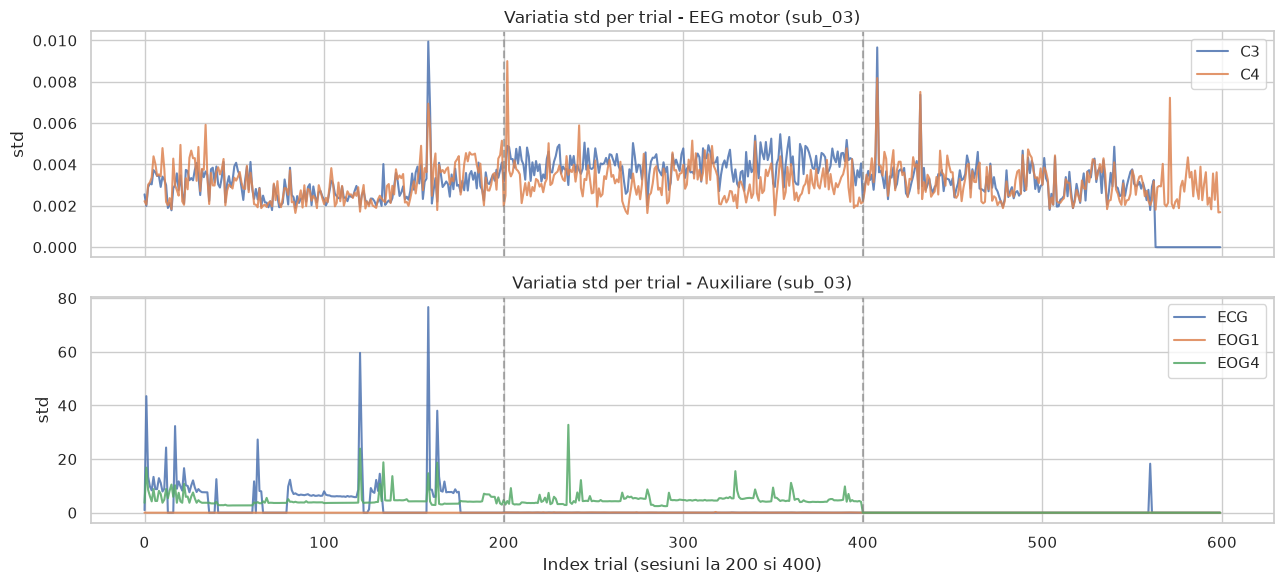

In [97]:
# Plot 17: Trial-by-trial std timeline for Subject 03 (C3 and ECG/EOG dropouts)

sub_check = 3 if 3 in subjects else subjects[-1]
d3 = np.load(cfg.get_subject_npz_path(sub_check), allow_pickle=True)
X_s3 = d3["X"]

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ch in ["C3", "C4"]:
    axes[0].plot(X_s3[:, cfg.MED_COLUMNS.index(ch), :].std(axis=1), label=ch, alpha=0.85)
axes[0].set_title(f"Variatia std per trial - EEG motor (sub_{sub_check:02d})")
axes[0].set_ylabel("std")
axes[0].legend()

for ch in ["ECG", "EOG1", "EOG4"]:
    axes[1].plot(X_s3[:, cfg.MED_COLUMNS.index(ch), :].std(axis=1), label=ch, alpha=0.85)
axes[1].set_title(f"Variatia std per trial - Auxiliare (sub_{sub_check:02d})")
axes[1].set_xlabel("Index trial (sesiuni la 200 si 400)")
axes[1].set_ylabel("std")
axes[1].legend()

for ax in axes:
    ax.axvline(200, color="gray", linestyle="--", alpha=0.6)
    ax.axvline(400, color="gray", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig(FIG_DIR / f"17_trial_std_timeline_sub{sub_check:02d}.png", dpi=150)
plt.show()
plt.close()

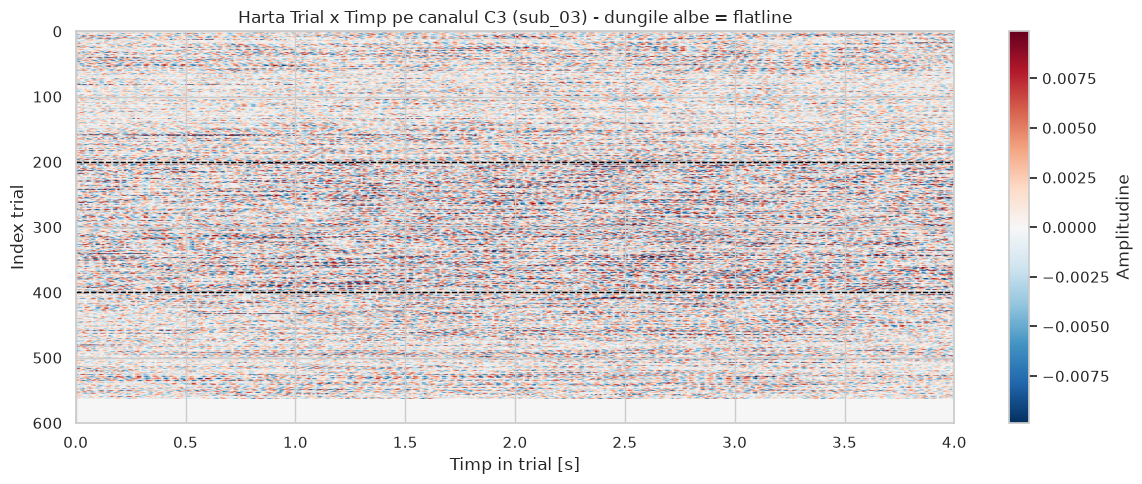

27245

In [98]:
# Plot 18: Trial x Time carpet heatmap for C3 on Subject 03 (flatlines stand out clearly)

c3_mat = X_s3[:, cfg.MED_COLUMNS.index("C3"), ::10]
vmax = float(np.percentile(np.abs(c3_mat), 99))

plt.figure(figsize=(12, 5))
plt.imshow(c3_mat, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, extent=[0, 4.0, len(c3_mat), 0])
plt.colorbar(label="Amplitudine")
plt.axhline(200, color="black", linestyle="--", linewidth=1)
plt.axhline(400, color="black", linestyle="--", linewidth=1)
plt.title(f"Harta Trial x Timp pe canalul C3 (sub_{sub_check:02d}) - dungile albe = flatline")
plt.xlabel("Timp in trial [s]")
plt.ylabel("Index trial")
plt.tight_layout()
plt.savefig(FIG_DIR / f"18_c3_trial_carpet_sub{sub_check:02d}.png", dpi=150)
plt.show()
plt.close()

del d3, X_s3, c3_mat
gc.collect()

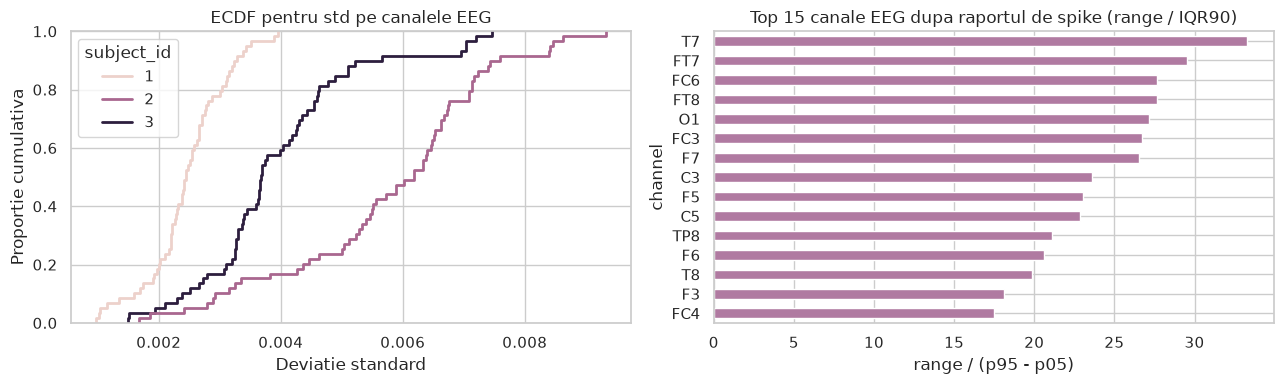

In [99]:
# Plot 19: ECDF of EEG channel std and Top 15 channels by outlier spike ratio

eeg_spike = eeg_only.copy()
eeg_spike["spike_ratio"] = eeg_spike["range"] / (eeg_spike["p95"] - eeg_spike["p05"])
top_spikes = eeg_spike.groupby("channel")["spike_ratio"].max().sort_values().tail(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.ecdfplot(data=eeg_spike, x="std", hue="subject_id", ax=axes[0], linewidth=2)
axes[0].set_title("ECDF pentru std pe canalele EEG")
axes[0].set_xlabel("Deviatie standard")
axes[0].set_ylabel("Proportie cumulativa")

top_spikes.plot(kind="barh", ax=axes[1], color="#B07AA1")
axes[1].set_title("Top 15 canale EEG dupa raportul de spike (range / IQR90)")
axes[1].set_xlabel("range / (p95 - p05)")

plt.tight_layout()
plt.savefig(FIG_DIR / "19_eeg_outlier_ecdf.png", dpi=150)
plt.show()
plt.close()

In [100]:
# Free temporary subject arrays from memory

del rep_data, X_rep, y_rep, eeg_flat, corr_df, pair_df
gc.collect()
print("Memoria a fost eliberata.")

Memoria a fost eliberata.


# 2.7 Salvarea tabelelor si raportului final

Salvam rezultatele per subiect, statisticile pe canale si distributia claselor in `reports/metrics/`, impreuna cu un sumar simplu Markdown.

In [101]:
# Combine per-subject results and save CSV files

summary_df = pq_df.merge(trial_df, on="subject_id").merge(quality_df, on="subject_id")
summary_df["needs_attention"] = (
    (summary_df["nulls"] > 0)
    | (summary_df["n_nan"] > 0)
    | (summary_df["n_inf"] > 0)
    | (~summary_df["rows_ok"])
    | (~summary_df["match_parquet"])
    | (summary_df["flatline_channels"] > 0)
    | (summary_df["partial_flatline_channels"] > 0)
    | (summary_df["extreme_var_eeg"] > 0)
)

summary_df.to_csv(cfg.METRICS_DIR / "eda_integritate.csv", index=False)
channel_df.to_csv(cfg.METRICS_DIR / "eda_canale_statistici.csv", index=False)
class_df.to_csv(cfg.METRICS_DIR / "eda_distributie_clase.csv", index=False)

print("CSV-uri salvate in reports/metrics/")
summary_df[["subject_id", "npz_trials", "sessions", "nulls", "n_nan", "n_inf", "flatline_channels", "partial_flatline_channels", "extreme_var_eeg", "needs_attention"]]

CSV-uri salvate in reports/metrics/


,subject_id,npz_trials,sessions,nulls,n_nan,n_inf,flatline_channels,partial_flatline_channels,extreme_var_eeg,needs_attention
0,1,600,"0,1,2",0,0,0,0,2,0,True
1,2,600,"0,1,2",0,0,0,0,2,0,True
2,3,600,"0,1,2",0,0,0,0,4,0,True


In [102]:
# Write a simple Markdown summary report

attention_list = summary_df[summary_df["needs_attention"]]["subject_id"].tolist()
md_lines = [
    "# Sumar EDA si Integritate (`01-data-analysis`)",
    "",
    f"- **Subiecti analizati:** {subjects}",
    f"- **Subiecti ce necesita atentie:** {attention_list}",
    f"- **Prag flatline:** `{FLATLINE_THRESHOLD}`",
    f"- **Prag varianta extrema EEG:** `>{EXTREME_VAR_MULTIPLIER}x` sau `<{LOW_VAR_MULTIPLIER}x` din mediana EEG",
    f"- **Canale semnalate:** {len(flagged_df)}",
    "",
    "## Tabel integritate per subiect\n",
    "```text\n",
    summary_df.to_string(index=False),
    "```",
]

report_path = cfg.METRICS_DIR / "eda_integritate.md"
report_path.write_text("\n".join(md_lines), encoding="utf-8")
print("Raport salvat la:", cfg.to_relative_path(report_path))

Raport salvat la: reports/metrics/eda_integritate.md
